In [ ]:
import pandas as pd

# Replace with your file name
file_path = "/content/100k-most-used-passwords-NCSC.txt"

with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
    passwords = [line.strip() for line in f]

len(passwords)

99840

In [ ]:
df = pd.DataFrame(passwords, columns=["password"])
df["length"] = df["password"].apply(len)

df.head()

,password,length
0,123456,6
1,123456789,9
2,qwerty,6
3,password,8
4,111111,6


In [ ]:
df["length"].describe()

,length
count,99840.000000
mean,7.363021
std,1.683743
min,0.000000
25%,6.000000
50%,7.000000
75%,8.000000
max,32.000000


In [ ]:
df["has_digits"] = df["password"].str.contains(r"\d")
df["has_letters"] = df["password"].str.contains(r"[a-zA-Z]")
df["has_symbols"] = df["password"].str.contains(r"[^\w\s]")
df["is_lowercase_only"] = df["password"].str.match(r"^[a-z]+$")


In [ ]:
df["has_repeats"] = df["password"].str.contains(r"(.)\1{2,}")

/tmp/ipython-input-3057623719.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["has_repeats"] = df["password"].str.contains(r"(.)\1{2,}")


In [ ]:
df["has_sequence"] = df["password"].str.contains(r"123|234|345|abc|bcd|qwerty")

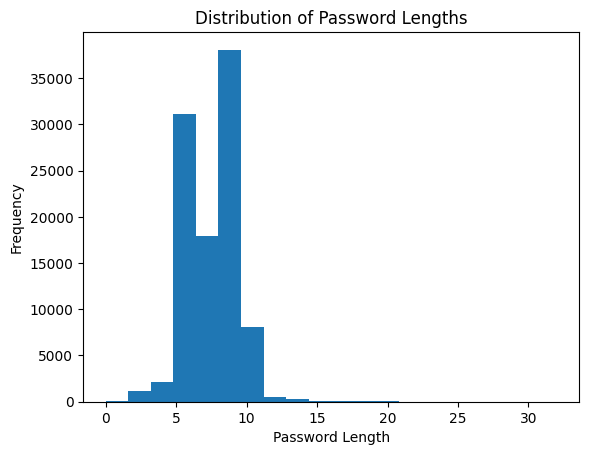

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df["length"], bins=20)
plt.title("Distribution of Password Lengths")
plt.xlabel("Password Length")
plt.ylabel("Frequency")
plt.show()


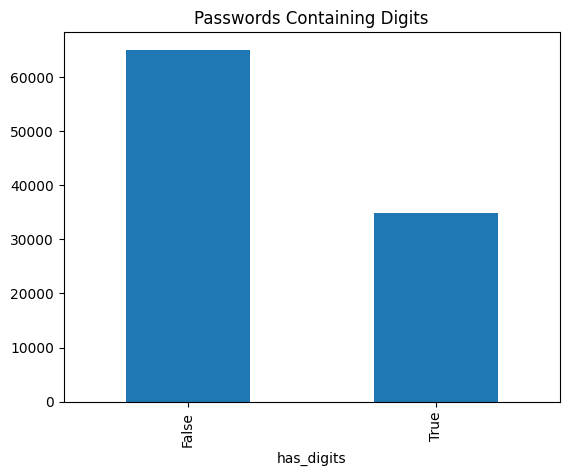

In [ ]:
df["has_digits"].value_counts().plot(kind="bar")
plt.title("Passwords Containing Digits")
plt.xticks([0, 1], ["False", "True"])
plt.show()


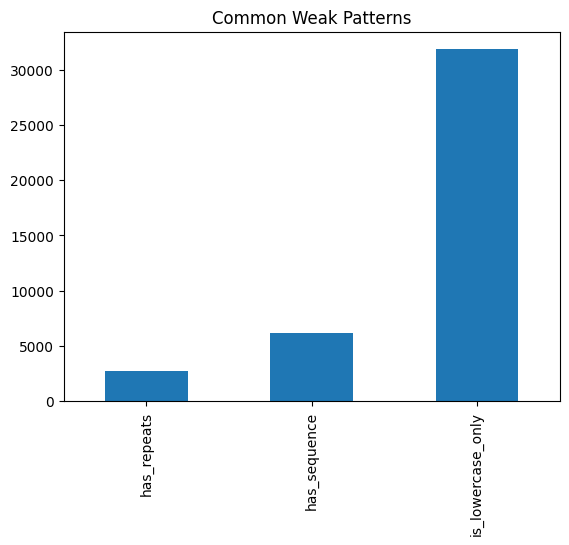

In [ ]:
pattern_counts = df[["has_repeats", "has_sequence", "is_lowercase_only"]].sum()
pattern_counts.plot(kind="bar")
plt.title("Common Weak Patterns")
plt.show()
